<a href="https://colab.research.google.com/github/raedbakhshh/Wisconsin-Breast-Cancer-Clustering-and-Classification/blob/main/Task1_Wisconsin_Breast_Cancer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd

In [ ]:
filepath = "/content/wdbc.data"
cancerdata = pd.read_csv(filepath)

It is a good practice to understand the dataframe, more specifically
the number of rows and columns given by the 'shape' function and the statistical
description of the dataframe given by the "describe()" function. I had suspected
that the column names were missing and to check that I used the "columns"
function.

In [ ]:

print(cancerdata.shape, '\n')
print(cancerdata.columns, '\n')
print(cancerdata.describe(), "\n")

(568, 32) 

Index(['842302', 'M', '17.99', '10.38', '122.8', '1001', '0.1184', '0.2776',
       '0.3001', '0.1471', '0.2419', '0.07871', '1.095', '0.9053', '8.589',
       '153.4', '0.006399', '0.04904', '0.05373', '0.01587', '0.03003',
       '0.006193', '25.38', '17.33', '184.6', '2019', '0.1622', '0.6656',
       '0.7119', '0.2654', '0.4601', '0.1189'],
      dtype='object') 

             842302       17.99       10.38       122.8         1001  \
count  5.680000e+02  568.000000  568.000000  568.000000   568.000000   
mean   3.042382e+07   14.120491   19.305335   91.914754   654.279754   
std    1.251246e+08    3.523416    4.288506   24.285848   351.923751   
min    8.670000e+03    6.981000    9.710000   43.790000   143.500000   
25%    8.692225e+05   11.697500   16.177500   75.135000   420.175000   
50%    9.061570e+05   13.355000   18.855000   86.210000   548.750000   
75%    8.825022e+06   15.780000   21.802500  103.875000   782.625000   
max    9.113205e+08   28.110000   39.2800

Since the dataset is not a traditional CSV it is hard to read it on Excel.
We can obtain the same information by using the "head()" function. By default
the "head()" function returns the first 5 rows of the dataframe.

In [ ]:
cancerdata.head(20)

,842302,M,17.99,10.38,122.8,1001,0.1184,0.2776,0.3001,0.1471,...,25.38,17.33,184.6,2019,0.1622,0.6656,0.7119,0.2654,0.4601,0.1189
0,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.18600,0.2750,0.08902
1,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.24300,0.3613,0.08758
2,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.25750,0.6638,0.17300
3,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.16250,0.2364,0.07678
4,843786,M,12.45,15.70,82.57,477.1,0.12780,0.17000,0.15780,0.08089,...,15.47,23.75,103.40,741.6,0.1791,0.5249,0.5355,0.17410,0.3985,0.12440
5,844359,M,18.25,19.98,119.60,1040.0,0.09463,0.10900,0.11270,0.07400,...,22.88,27.66,153.20,1606.0,0.1442,0.2576,0.3784,0.19320,0.3063,0.08368
6,84458202,M,13.71,20.83,90.20,577.9,0.11890,0.16450,0.09366,0.05985,...,17.06,28.14,110.60,897.0,0.1654,0.3682,0.2678,0.15560,0.3196,0.11510
7,844981,M,13.00,21.82,87.50,519.8,0.12730,0.19320,0.18590,0.09353,...,15.49,30.73,106.20,739.3,0.1703,0.5401,0.5390,0.20600,0.4378,0.10720
8,84501001,M,12.46,24.04,83.97,475.9,0.11860,0.23960,0.22730,0.08543,...,15.09,40.68,97.65,711.4,0.1853,1.0580,1.1050,0.22100,0.4366,0.20750
9,845636,M,16.02,23.24,102.70,797.8,0.08206,0.06669,0.03299,0.03323,...,19.19,33.88,123.80,1150.0,0.1181,0.1551,0.1459,0.09975,0.2948,0.08452


Upon getting a more structured look at the dataframe with the help of
the "head()" function and the "column" function, the dataframe is missing
column names

I need to look at the various classes in the second column of the dataframe.This can be achieved by the "unique()" funciton which returns an array of all the unique classes of the specific row. "value_counts()" returns the frequency of each of the unique classese of the specific column


In [ ]:
cancerdata["M"].unique()
cancerdata["M"].value_counts()

,count
M,
B,357
M,211


# **Setting the Column Names**
I'll gather the name of the columns as mentioned in the UC Irvine web page, whihc is the source of this dataset. I'll put the names of the column  in a list variable

In [ ]:
col_names = [
    'ID', 'Diagnosis', 'radius1', 'texture1', 'perimeter1', 'area1', 'smoothness1',
    'compactness1', 'concavity1', 'concave_points1', 'symmetry1', 'fractal_dimension1',
    'radius2', 'texture2', 'perimeter2', 'area2', 'smoothness2', 'compactness2',
    'concavity2', 'concave_points2', 'symmetry2', 'fractal_dimension2', 'radius3',
    'texture3', 'perimeter3', 'area3', 'smoothness3', 'compactness3', 'concavity3',
    'concave_points3', 'symmetry3', 'fractal_dimension3'
]

In [ ]:
cancerdata = pd.read_csv(filepath, header = None, names=col_names, index_col = "ID" )

I have overwritten the "cancerdata" variable with the updated dataframe which has the correct column names and the dataframe is indexed by the "ID" column. "header" argument is used to determine whether the first row of the dataset is the column name or not. Since our dataset doesn't have column names, we set this argument as "None".
The "names" argument is used to assign the name of the columns. It takes a list of column names and assigns it to each of the column in the same order it is presented in the list.
Once the names of the columns are set accordingly, the "index_col" argument is used to assign a specific column of as the index of the dataframe. The value of "index_col" must be the name of the column we wish to assign as index, in my case it is the "ID" column,

We will first look at the first 5 rows of the dataframe using the "head()" function, to make sure if the column names have been assigned in the right order and then look at the statistical description of the data.

In [ ]:
cancerdata.head()

,Diagnosis,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,...,radius3,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3
ID,,,,,,,,,,,,,,,,,,,,,
842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [ ]:
cancerdata.describe()

,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,fractal_dimension1,...,radius3,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


In [ ]:
print(cancerdata["Diagnosis"].value_counts())
cancerdata.shape

Diagnosis
B    357
M    212
Name: count, dtype: int64


(569, 31)

Prior to setting the index column and the names of the column, the shape of the dataframe was (568,32) since the first row of the column was taken as the column header and the first column wasn't the index. But now, since the first row is no no longer the header and the first column is the index, the shape of the dataframe is (569,31).

# CHECK FOR MISSING VALUES

In [ ]:
#check for any missing value in the dataset
cancerdata.isnull().values.any()

np.False_

In [ ]:
#check columns for any missing value
cancerdata.isnull().any()

,0
Diagnosis,False
radius1,False
texture1,False
perimeter1,False
area1,False
smoothness1,False
compactness1,False
concavity1,False
concave_points1,False
symmetry1,False


In [ ]:
#check for total number of missing rows in each columns
cancerdata.isna().sum()

,0
Diagnosis,0
radius1,0
texture1,0
perimeter1,0
area1,0
smoothness1,0
compactness1,0
concavity1,0
concave_points1,0
symmetry1,0


The dataset does not having missing values.


# CHECK FOR DUPLICATE ROWS

In [ ]:
#check the dataframe for any duplicate rows
cancerdata.duplicated().any()

np.False_

In [ ]:
#check the dataframe for total number of duplicate rows
x = cancerdata.duplicated().sum()
print(x)

0


In [ ]:
#collect the duplicated rows of the dataframe except the first occurence
duplicated_rows = cancerdata[cancerdata.duplicated(keep = "first")]


In [ ]:
#drop all the duplicate rows
cancerdata = cancerdata.drop_duplicates()
cancerdata.shape

(569, 31)

the dataset has no duplicate rows either

# STATISTICAL DESCRIPTION OF EACH COLUMN AND BOX PLOT

In [ ]:
for col in cancerdata.columns:
   print(col)
   print(cancerdata[col].describe(), '\n')



Diagnosis
count     569
unique      2
top         B
freq      357
Name: Diagnosis, dtype: object 

radius1
count    569.000000
mean      14.127292
std        3.524049
min        6.981000
25%       11.700000
50%       13.370000
75%       15.780000
max       28.110000
Name: radius1, dtype: float64 

texture1
count    569.000000
mean      19.289649
std        4.301036
min        9.710000
25%       16.170000
50%       18.840000
75%       21.800000
max       39.280000
Name: texture1, dtype: float64 

perimeter1
count    569.000000
mean      91.969033
std       24.298981
min       43.790000
25%       75.170000
50%       86.240000
75%      104.100000
max      188.500000
Name: perimeter1, dtype: float64 

area1
count     569.000000
mean      654.889104
std       351.914129
min       143.500000
25%       420.300000
50%       551.100000
75%       782.700000
max      2501.000000
Name: area1, dtype: float64 

smoothness1
count    569.000000
mean       0.096360
std        0.014064
min        0.0526

Using box plots to visualize the statistical description of the features

In [ ]:
X = cancerdata.drop("Diagnosis", axis = 1)
y = cancerdata["Diagnosis"]

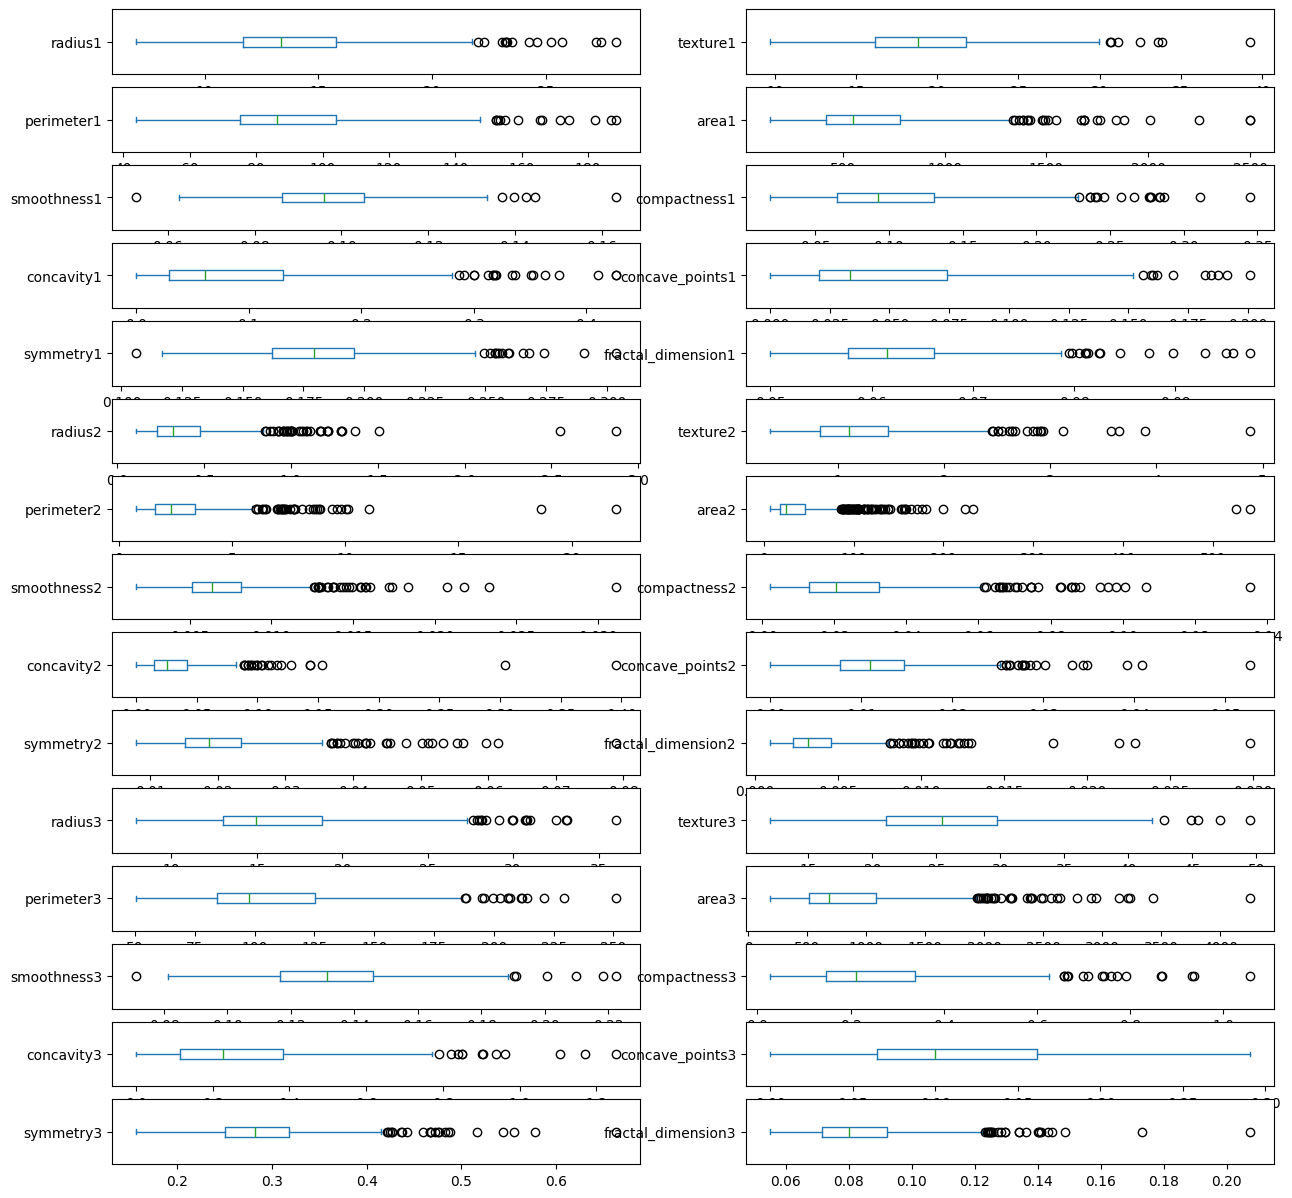

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer



X.plot(kind='box', subplots=True, layout=(15, 2), figsize=(15, 15), vert=False, sharex=False)

plt.show()

Looking at the statistical description, it is clear the magntitudes of the features are not in the same range. Some featurs have extremely high magnitudes and some really low. Machine learning models work on mathematical equations. The features x_1 to x_n are the independent variables. The function f(x_1, ..., x_n) predicts the target variable. Features with high magnitudes will dominate to dominate the equation. The equation to be solved in order to predict the target value is the Machine Learning Algorithm. In other words, the machine learning algorithm will be highly biased towards features with higher magnitudes.

The boxplot demonstrates that there are significant amount of outliers in the each of the features. However, these outliers are important and must not be removed. If the outliers are removed from the dataset, the model will not learn the patterns of these outliers. In such a case, a set of features, which are way outside the range of the values the dataset was trained (outliers), the model will inaccurately  predict the diagnosis with high confidence. This will result in a False Negative or a missed case, which can be costly for cancer diagnosis.

The dataset contains features in 3 main subsets: the mean with the suffix "1", the standard error with the suffix "2"and the worst with the suffix "3".

# REDUCING DIMENSIONALITY BY DROPPING REDUNDANT FEATURES USING CORRELATION MATRIX
Features such as perimeter, radius, area and compactness determine the size of the cells. While, concave points, concavity and symmetery determine the shape of the cells. There is a high correlation amongst these features which can be discovered using a Correlation Matrix

In [ ]:
Corr_matrix = X.corr()
Corr_matrix

,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,fractal_dimension1,...,radius3,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3
radius1,1.000000,0.323782,0.997855,0.987357,0.170581,0.506124,0.676764,0.822529,0.147741,-0.311631,...,0.969539,0.297008,0.965137,0.941082,0.119616,0.413463,0.526911,0.744214,0.163953,0.007066
texture1,0.323782,1.000000,0.329533,0.321086,-0.023389,0.236702,0.302418,0.293464,0.071401,-0.076437,...,0.352573,0.912045,0.358040,0.343546,0.077503,0.277830,0.301025,0.295316,0.105008,0.119205
perimeter1,0.997855,0.329533,1.000000,0.986507,0.207278,0.556936,0.716136,0.850977,0.183027,-0.261477,...,0.969476,0.303038,0.970387,0.941550,0.150549,0.455774,0.563879,0.771241,0.189115,0.051019
area1,0.987357,0.321086,0.986507,1.000000,0.177028,0.498502,0.685983,0.823269,0.151293,-0.283110,...,0.962746,0.287489,0.959120,0.959213,0.123523,0.390410,0.512606,0.722017,0.143570,0.003738
smoothness1,0.170581,-0.023389,0.207278,0.177028,1.000000,0.659123,0.521984,0.553695,0.557775,0.584792,...,0.213120,0.036072,0.238853,0.206718,0.805324,0.472468,0.434926,0.503053,0.394309,0.499316
compactness1,0.506124,0.236702,0.556936,0.498502,0.659123,1.000000,0.883121,0.831135,0.602641,0.565369,...,0.535315,0.248133,0.590210,0.509604,0.565541,0.865809,0.816275,0.815573,0.510223,0.687382
concavity1,0.676764,0.302418,0.716136,0.685983,0.521984,0.883121,1.000000,0.921391,0.500667,0.336783,...,0.688236,0.299879,0.729565,0.675987,0.448822,0.754968,0.884103,0.861323,0.409464,0.514930
concave_points1,0.822529,0.293464,0.850977,0.823269,0.553695,0.831135,0.921391,1.000000,0.462497,0.166917,...,0.830318,0.292752,0.855923,0.809630,0.452753,0.667454,0.752399,0.910155,0.375744,0.368661
symmetry1,0.147741,0.071401,0.183027,0.151293,0.557775,0.602641,0.500667,0.462497,1.000000,0.479921,...,0.185728,0.090651,0.219169,0.177193,0.426675,0.473200,0.433721,0.430297,0.699826,0.438413
fractal_dimension1,-0.311631,-0.076437,-0.261477,-0.283110,0.584792,0.565369,0.336783,0.166917,0.479921,1.000000,...,-0.253691,-0.051269,-0.205151,-0.231854,0.504942,0.458798,0.346234,0.175325,0.334019,0.767297


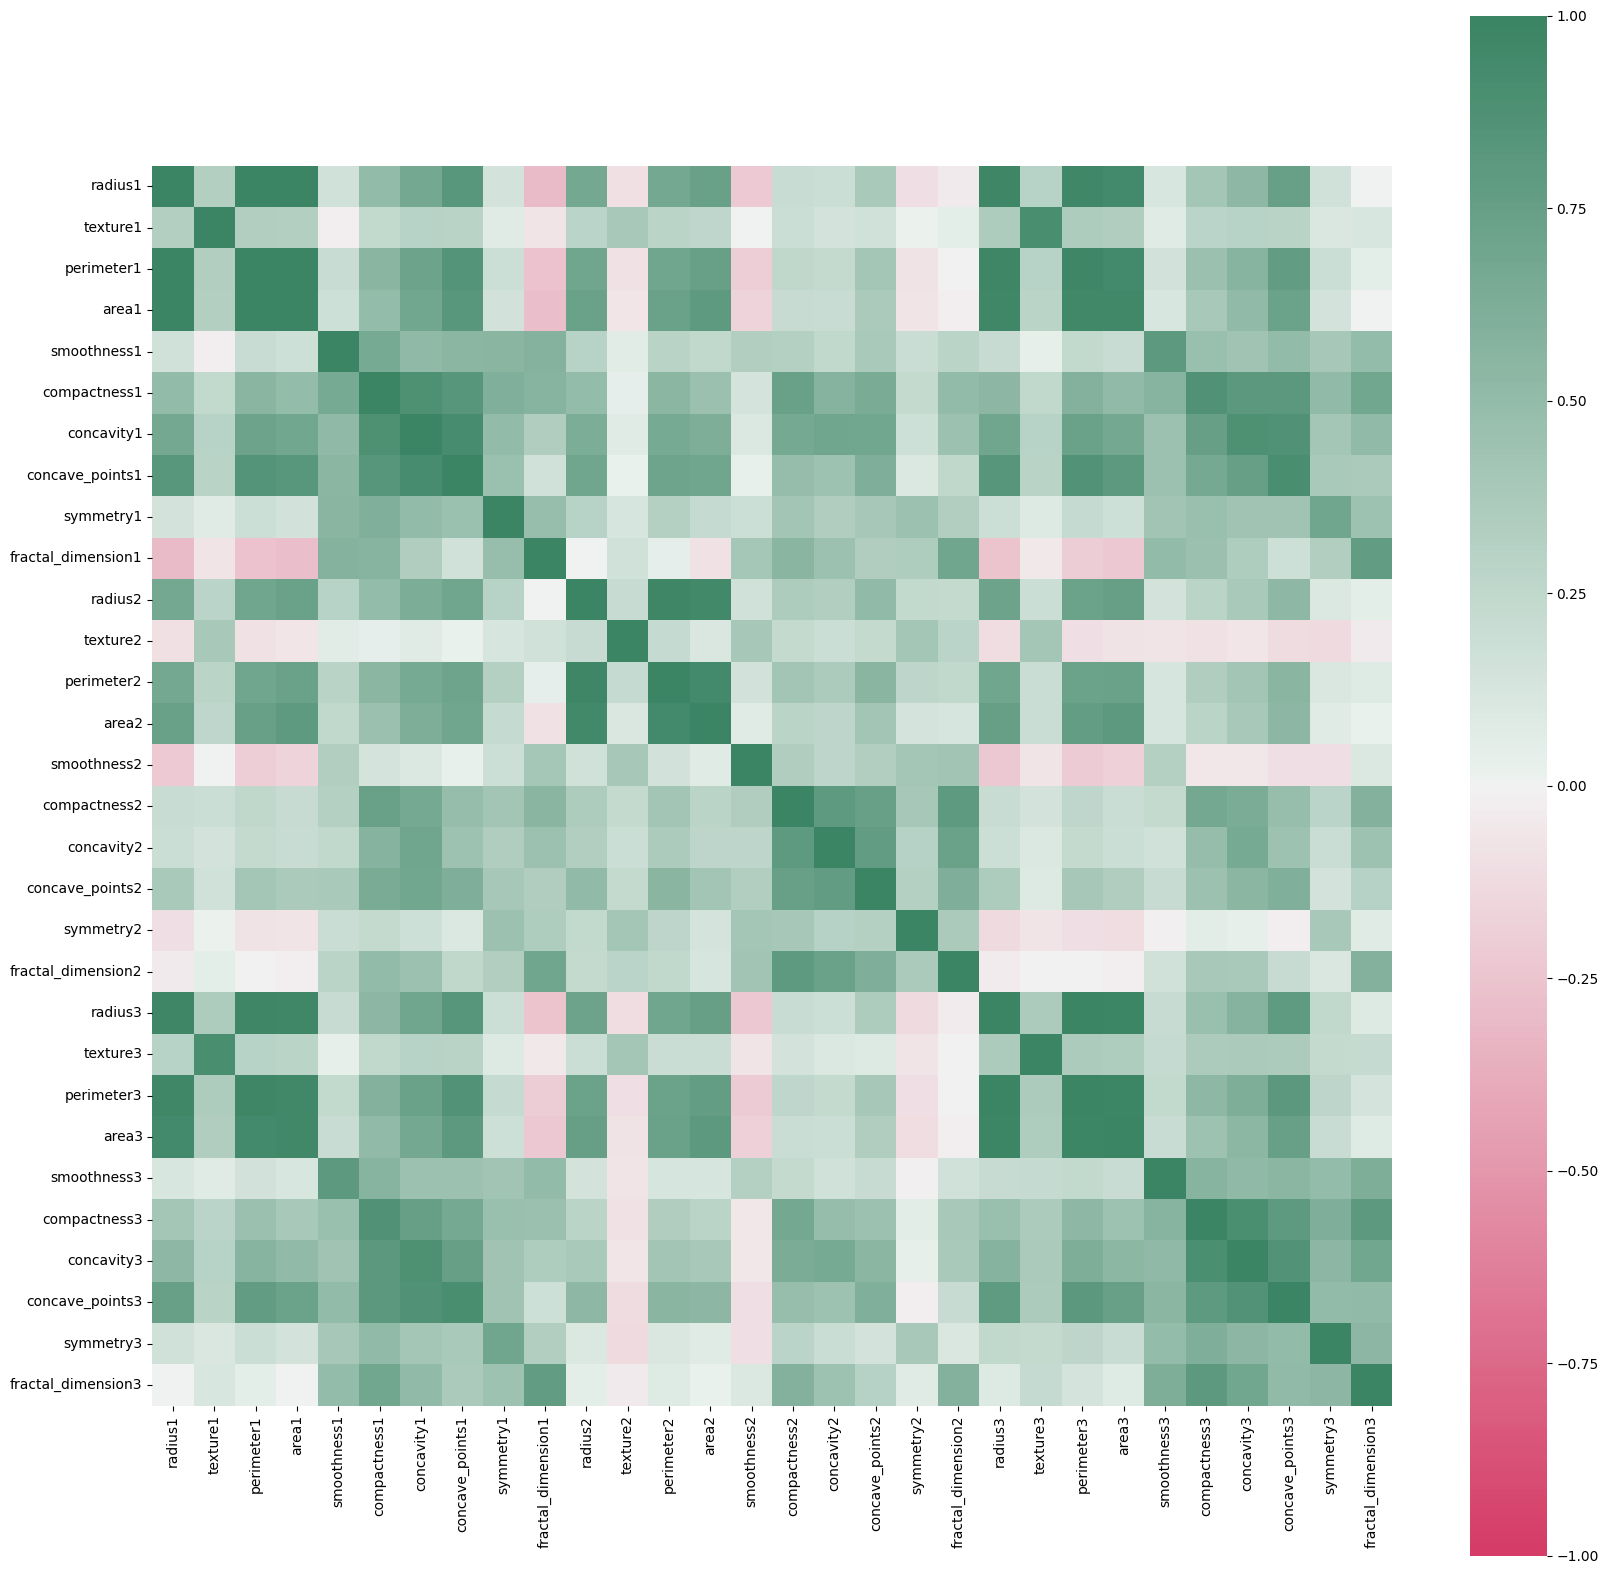

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(20, 20))
axis_corr = sns.heatmap(
    Corr_matrix,
    vmin=-1, vmax=1, center=0,
    cmap=sns.diverging_palette(1, 150, n=1000),
    square=True
)
plt.show()

The heatmap of correlation matrix helps to visualize the degree of correlation between the featres. Most of the features are highly correlated but it may not always be neccessary to drop the higly correlated the features. It depends on the model we choose. Tree-based classifier are highly immune to multicollinearity, whereas for distance-based models such as logistic regression struggle with multicollinearity as the algorithm finds it difficult to assign the weights to the multicollinear data. In a set of features that are highly correlated, we select one feature and drop the remaining.

From the correlation radius1, perimeter1, area1, radius3, perimeter3, area3 are highly correlated to each other. We can keep one of the features while dropping the remaining, since mathematically they convey the same meaning to the model. Hence, removing the features will redunce redundancy.


Concavity1 and concave_points1 and concave_points1 and concave_points3 have a very high correlation but concavity1 and concave_points3 don't have a very high correlation. Moreover, concavity1, concave_points3 and concavity3 have a lower correlaion value. It is safe to drop concave_points1.

To select the best candidate amongst radius1, perimeter1, area1, radius3, perimeter3 and area3 we will have to look at there Mutual Information Score as they can detect any linear and non-linear relationship between the target and the variables. But they can only be used for supervised learning, since it requires the target values.

The data set must be split into train and test split before standardization and MI scores to prevent data leakage.

To compute MI score the target series "y" must be label encoded


In [ ]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
y = le.fit_transform(y)
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

In [ ]:
X.columns

Index(['radius1', 'texture1', 'perimeter1', 'area1', 'smoothness1',
       'compactness1', 'concavity1', 'concave_points1', 'symmetry1',
       'fractal_dimension1', 'radius2', 'texture2', 'perimeter2', 'area2',
       'smoothness2', 'compactness2', 'concavity2', 'concave_points2',
       'symmetry2', 'fractal_dimension2', 'radius3', 'texture3', 'perimeter3',
       'area3', 'smoothness3', 'compactness3', 'concavity3', 'concave_points3',
       'symmetry3', 'fractal_dimension3'],
      dtype='object')

In [ ]:
print(type(y))

<class 'numpy.ndarray'>


In [ ]:
from sklearn.feature_selection import mutual_info_regression


def make_mi_scores(X, y):
    mi_scores = mutual_info_regression(X, y)
    mi_scores = pd.Series(mi_scores, name="MI Scores", index=X.columns)
    mi_scores = mi_scores.sort_values(ascending=False)
    return mi_scores

mi_scores = make_mi_scores(X_train, y_train)
print(mi_scores)

radius3               0.462263
perimeter3            0.455619
area3                 0.453342
concave_points1       0.443994
concave_points3       0.427855
perimeter1            0.409947
area1                 0.375136
radius1               0.368662
concavity1            0.352741
area2                 0.345444
concavity3            0.298782
perimeter2            0.263918
radius2               0.227432
compactness1          0.219859
compactness3          0.219761
texture3              0.143345
concave_points2       0.133096
smoothness1           0.105449
symmetry3             0.104707
smoothness3           0.100104
concavity2            0.095696
fractal_dimension3    0.075392
texture1              0.074325
symmetry1             0.073249
compactness2          0.045243
fractal_dimension2    0.040142
symmetry2             0.026674
smoothness2           0.002631
texture2              0.000000
fractal_dimension1    0.000000
Name: MI Scores, dtype: float64


From the MI scores, the highest one is Perimeter 3. Amongst area1, radius1, perimeter1, area3, radius3, perimeter3, we keep perimeter3 and drop the remaining. Between concave_points1, concavity1 and concave_points3, concave_points1 have the highest score and a strong correlaion with both, hence we keep concave_points1 and drop the remaining. Always compare the correlation value and the mi score between the features before making a decison to drop them. All features with a MI Score less than 0.05 can be dropped.

In [ ]:
X_train = X_train.drop(["area1", "radius1", "perimeter1", "texture1", "area3", "radius3", "texture2", "fractal_dimension1", "symmetry2", "smoothness2", "fractal_dimension2"], axis=1)
X_test= X_test.drop(["area1", "radius1", "perimeter1", "area3", "texture1", "radius3", "texture2", "fractal_dimension1", "symmetry2", "smoothness2", "fractal_dimension2"], axis=1)


<Axes: >

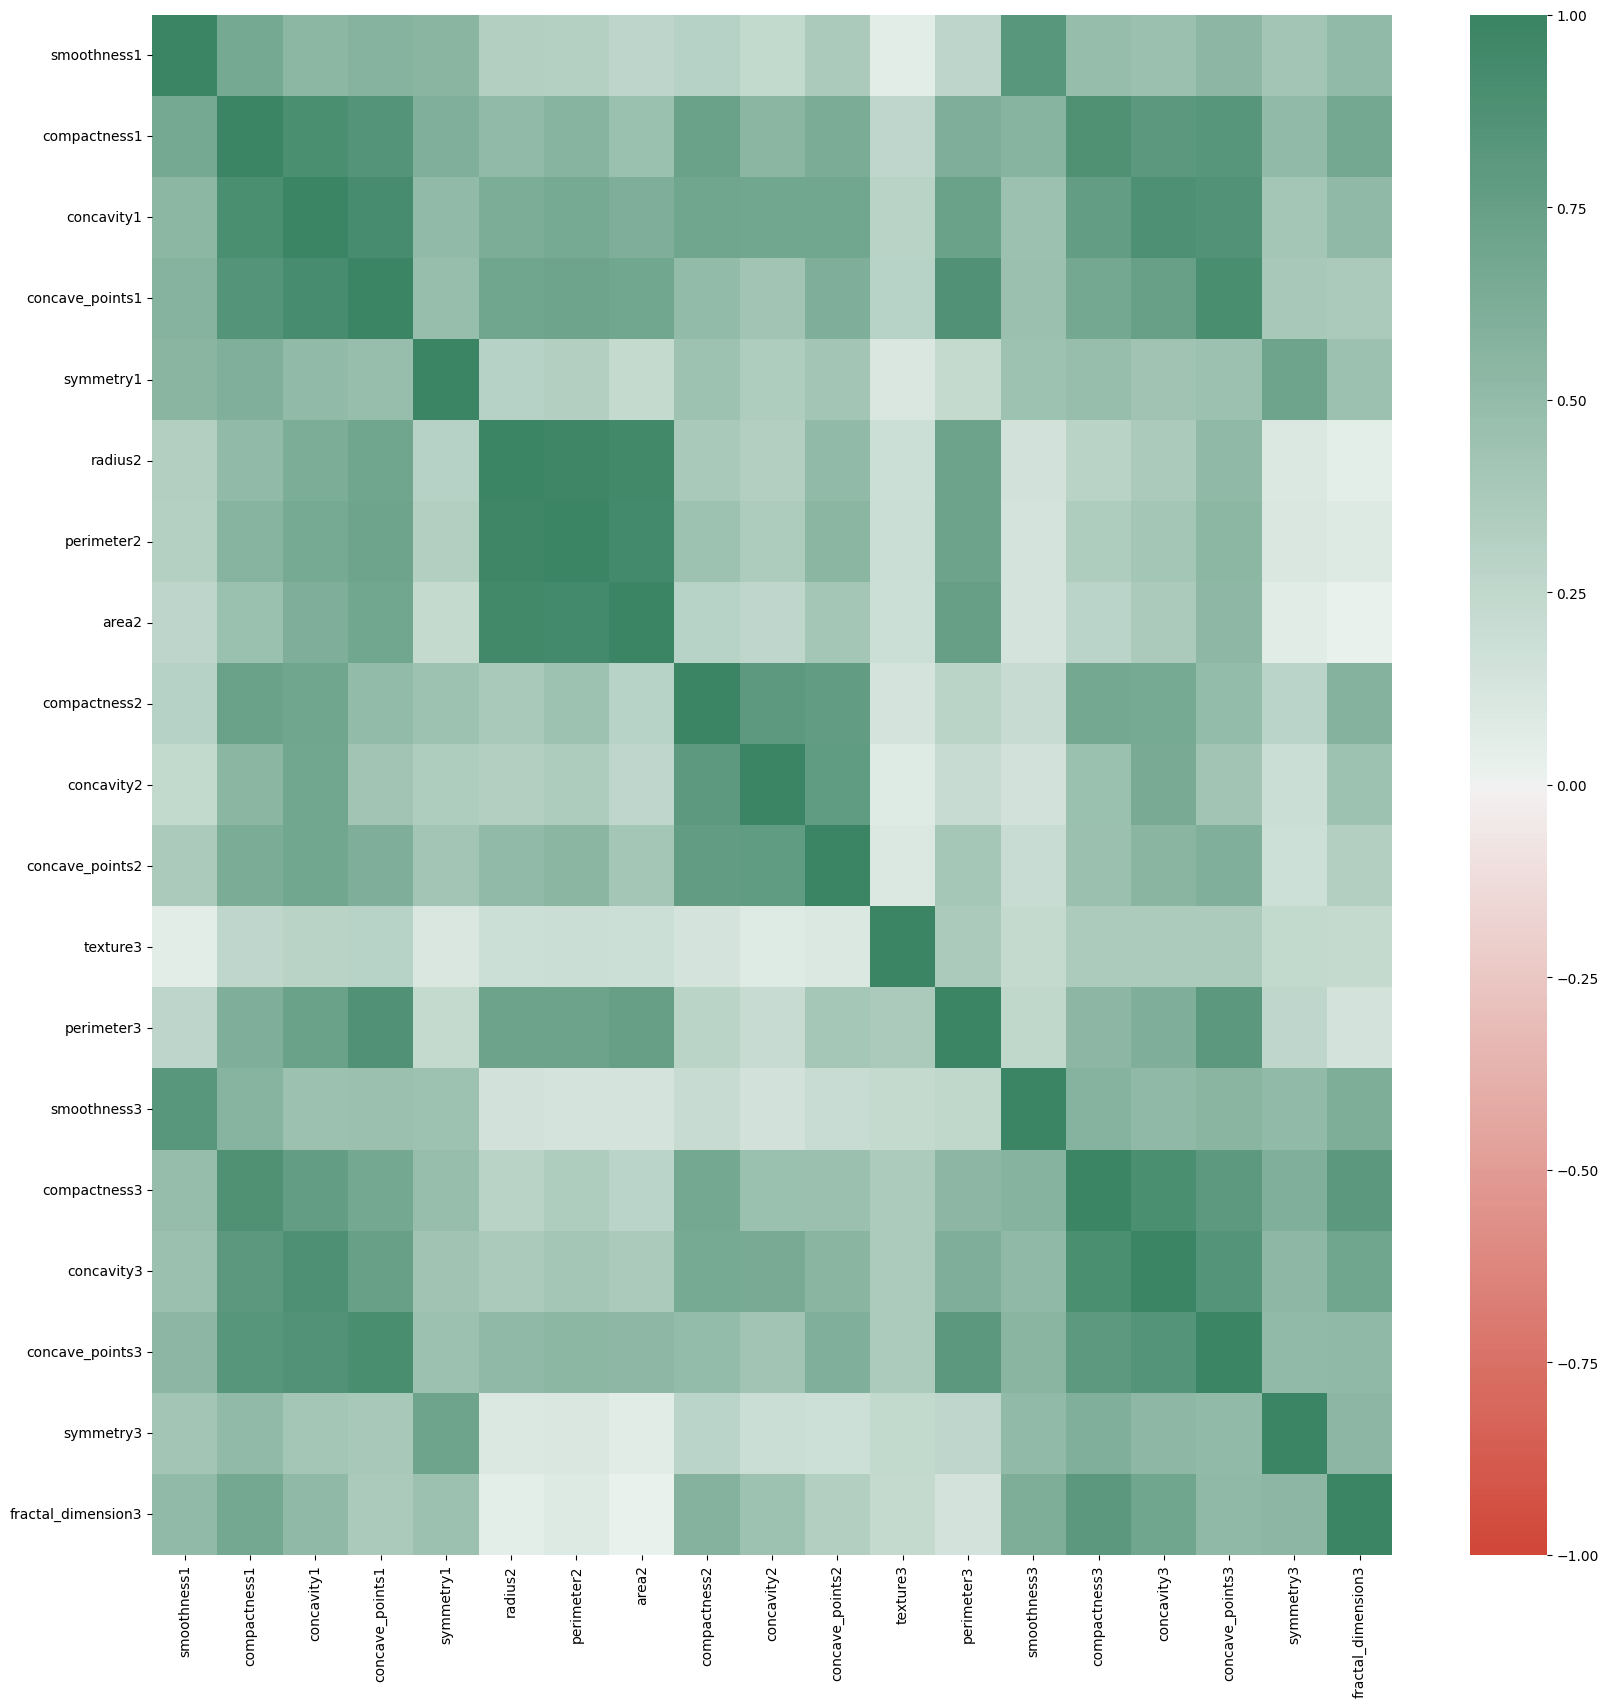

In [ ]:
Corr_matrix = X_train.corr()
Corr_matrix
plt.figure(figsize = (20,20))
sns.heatmap(
    Corr_matrix,
    vmin = -1,
    vmax = 1,
    center = 0,
    cmap=sns.diverging_palette(15,150,n=1000),
    fmt='g')

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix

In [ ]:
preprocessor  = StandardScaler()
model1 = LogisticRegression(max_iter=1000)
model2 = RandomForestClassifier(n_estimators=100, random_state=42)

# Logistic Regression: USING CONFUSION MATRIX TO EVALUATE TRAIN TEST SPLIT

In [ ]:
my_pipeline1= Pipeline(steps=[('preprocessor', preprocessor),
                              ('model', model1)
                             ])
my_pipeline1.fit(X_train, y_train)
preds1 = my_pipeline1.predict(X_test)


In [ ]:
model1_matrix = confusion_matrix(y_test, preds1)
print(model1_matrix)

[[71  1]
 [ 2 40]]


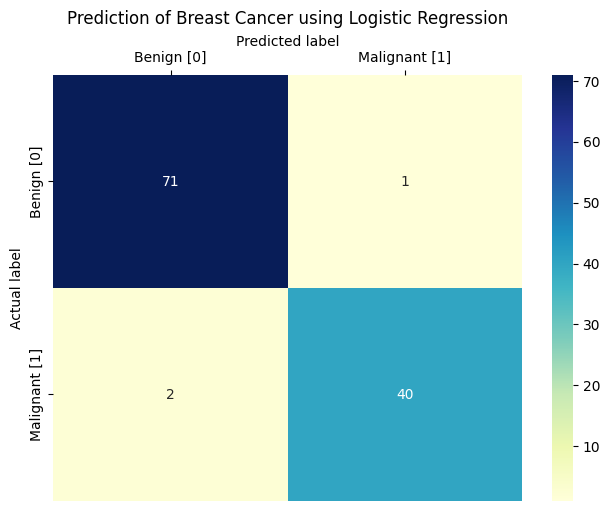

In [ ]:
class_names = ["Benign [0]", "Malignant [1]"]
fig, ax = plt.subplots()
tick_marks = np.arange(len(class_names))
plt.xticks(tick_marks, class_names)
plt.yticks(tick_marks, class_names)

sns.heatmap(
    pd.DataFrame(model1_matrix),
    annot=True,
    cmap="YlGnBu",
    fmt='g',
    xticklabels=class_names,
    yticklabels=class_names)


ax.xaxis.set_label_position("top")
ax.xaxis.tick_top()
plt.tight_layout()
plt.title('Prediction of Breast Cancer using Logistic Regression', y=1.1)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
ax.yaxis.set_label_position("left")


In [ ]:
print(classification_report(y_test, preds1))

              precision    recall  f1-score   support

           0       0.97      0.99      0.98        72
           1       0.98      0.95      0.96        42

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



# Random Forest Classifier: USING CONFUSION MATRIX TO EVALUATE TRAIN TEST SPLIT

In [ ]:
my_pipeline2= Pipeline(steps=[('preprocessor', preprocessor),
                              ('model', model2)
                             ])

my_pipeline2.fit(X_train, y_train)
preds2 = my_pipeline2.predict(X_test)

In [ ]:
model2_matrix = confusion_matrix(y_test, preds2)
print(model2_matrix)

[[72  0]
 [ 4 38]]


Text(0.5, 451.67777777777775, 'Predicted label')

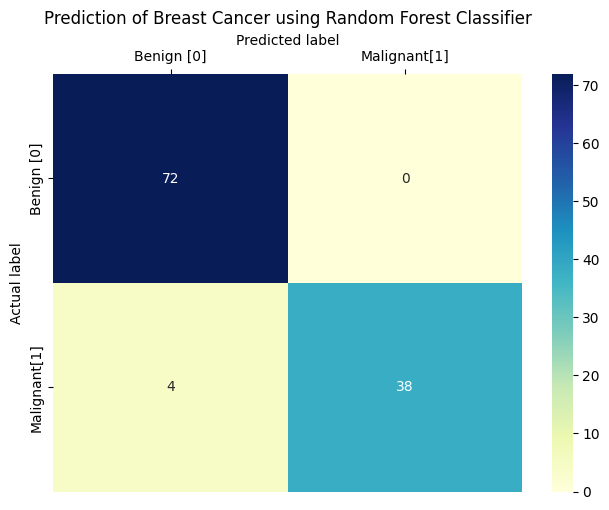

In [ ]:
class_names = ["Benign [0]", "Malignant[1]"]
fig, ax = plt.subplots()
tick_marks = np.arange(len(class_names))
plt.xticks(tick_marks, class_names)
plt.yticks(tick_marks, class_names)

sns.heatmap(
    pd.DataFrame(model2_matrix),
    annot=True,
    cmap="YlGnBu",
    fmt='g',
    xticklabels=class_names,
    yticklabels=class_names)
ax.xaxis.set_label_position("top")
ax.xaxis.tick_top()
plt.tight_layout()
plt.title('Prediction of Breast Cancer using Random Forest Classifier', y=1.1)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')

In [ ]:
print(classification_report(y_test, preds2))

              precision    recall  f1-score   support

           0       0.95      1.00      0.97        72
           1       1.00      0.90      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.95      0.96       114
weighted avg       0.97      0.96      0.96       114



# USING CROSS-VALIDATION

In [ ]:
from sklearn.model_selection import cross_val_score
scores1 = cross_val_score(my_pipeline1, X, y, scoring = "accuracy")

print("accuracy scores for Logistic Regression: ", scores1.mean())

accuracy scores for Logistic Regression:  0.9806862288464524


In [ ]:
scores2 = cross_val_score(my_pipeline2, X, y, scoring = "accuracy")
print("accuracy scores for Random Forest Classifier: ", scores2.mean())

accuracy scores for Random Forest Classifier:  0.9560937742586555


# CLUSTERING

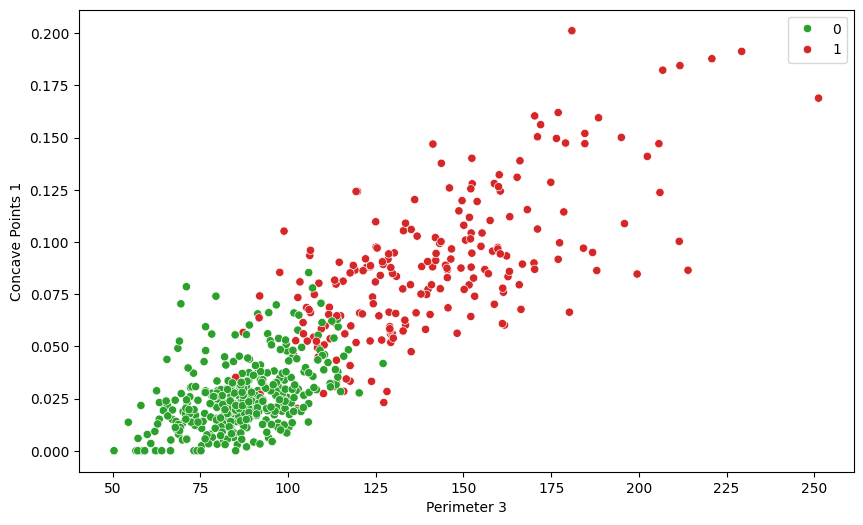

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=cancerdata, x="perimeter3", y= "concave_points1",hue=y, palette=['#2ca02c', '#d62728'])
plt.xlabel("Perimeter 3")
plt.ylabel("Concave Points 1")
plt.show()

Principle Component Analysis computes the direction of highest variation considering all the features, although we can use a a subset of features too. It fits a line through the cluster in the direction of the maximum variation known as Principle Component 1. The line perpendicular to the PC1 is axis of second highest variance, known as PC2. Principle Component Analysis is extremely helpful for dimensionality reduction and to visualize the data set using all of its features.


The Wisconsin Breast Cancer data contains 30 features, in which highly correlated features were dropped. Regardless of those, it is impossible to visualize something greater than 3 dimensions. Hence we use PCA, to transform the dimensions down to two dimensions and visualize it.


PCA handles mutlicollinearity. Dropping columns using correlation matrix beforehand will be counterproductive to PCA, as it result in the loss of information which could have been useful to the PCA.


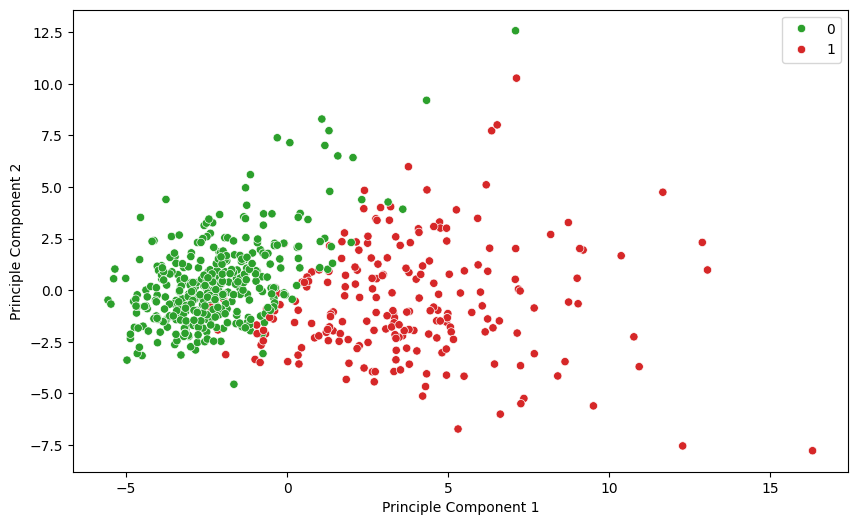

In [ ]:
from sklearn.decomposition import PCA
pca_vis = PCA(n_components=2)

my_pca_vis_pipeline = Pipeline(steps=[('preprocessor', preprocessor),
                              ('pca', pca_vis)
                             ])
pca_data_vis=my_pca_vis_pipeline.fit_transform(X)

plt.figure(figsize=(10, 6))
sns.scatterplot(x=pca_data_vis[: , 0], y=pca_data_vis[: ,1],hue=y, palette=['#2ca02c', '#d62728'])
plt.xlabel("Principle Component 1")
plt.ylabel("Principle Component 2")
plt.show()

In [ ]:
pca = PCA(n_components=15)
from sklearn.preprocessing import PowerTransformer
preproccesor1 = PowerTransformer(method = "yeo-johnson")
my_pca_pipeline = Pipeline(steps=[('preprocessor', preprocessor),
                              ('pca', pca)
                             ])
pca_data=my_pca_pipeline.fit_transform(X)

Benign (non-cancerous) cells have similar features to one another, while Malignant (cancerous) cells have highly varying features to one another. This behavious of cancerous and non-cancerous cells have been captured very well by the PCA. The non-cancerous cells are low variance and clustered near to each other, whereas the cancerous cells have high variance and spread out all over the plot. In conclusion, we get to dilute our data set down to two features while retaining all the useful information with the help of PCA.


Applying a clustering algorithm that can differentiate the data clouds based on the compactness will be effective.

# DISSIMILARIY AND SIMILARITY IN CLUSTERING
Distance(dissimilarity) and similarity are the mathematical quantities the clustering algorithms use to group the data points together.



There are mainly two types of data: quantitave and qualitative. Quantitative datas are information associated with measurement of an object such as pressure, height, count, temparature etc. For quantitatives, dissimilarity is preffered to recognize the relationship between the data points.



Qualitatives are non-measurble information of an object, more to do with the qualities of the object such as color. They are mainly categorical and can be nominal or ordinal. Similarity is preffered while dealing with qualitative data.

# INTERNAL AND EXTERNAL EVALUATION

*Internal Evaluation* : the algorithm performance is evaluated based on the data set itself since "the real truth" isn't available. However, in comparing two or more algorithm, a better score of an algorithm in comparison to the rest doesn't not equate that algorithm being better. It cannot absolutely judge the algorithms. It evaluates compactness (how compact the data points in a cluster are) and seperation (how far apart the clusters are). Silhouette Coefficient, Dunn Indicator and Davies-Bouldin Indicator.


*External Evaluation* : the algorithm's performance is judged against the "real ground-truth" and is the gold standard for evaluation. Rand Indicator, F Indicator, Confusion Matrix, Jaccard Indicator, Fowlkes–Mallows
indicator, Mutual Information.

# CLUSTERING BASED ON PARTITIONS : K-MEANS

K-Means Clustering is an unsupervised learning algorithm, which partitions the entire data cloud into "K" clusters. K-Means iteratively update the center of the cluster until it is stable (meaning it doesn't change much). It keeps updating the centeroid such that it should be represented by the mean of the data cluster. It works on the assumption that the clusters are isotropic and
convex.


What is an isotropic cluser ?


An isotropic cluster is a cluster with equal variance in all direction. Variance is the average of the sum of squared euclidean distance between mean of the data and the data points. It is basically the dispersion of the data points around the mean. A perfectly spherical cluster is an example, because in every possible direction it has an equal spread.


What is a convex cluster ?


A cluster is said to be convex if the "distance" line can be drawn between any two points without ever leaving the cluster


In order to understand the importance of these, it is neccessary to understand the working of K-means algorithms. K-means algorithm assigns "k" random data points as the *centroid* and computes the distance between each point and each centroid. It iteratively clusters data points that are the closest to the *centroid* and re-calculates the mean of the cluster. It iteratively results in minimimizng the cost function - within cluster sum of sqaure variance. If the algorithm is minimizing the WCSS variance, that means it is assuming the data cloud is Isotropic, because isotropic clouds have the lowest WCSS variance.     Suppose if the clusters are non-convex shapes such as: concentric circles or a bunch of crescent-shaped circles, the algorithm fails miserably. It doesn't know the shape of clusters, it simply iteratively assign points to mean and updates the mean until it results in a cluster (acting as circle) centered around the final mean. Informally one could think of it as k-means using all the data points in the cloud, to compute and divide the data points of the clouds into "k" circles, with center as the mean each with the least possible radius of capture. all data points within these radius are grouped together. If two circles overlap, a perpendicular bisector is drawn at the overlapping region.


Mean is basically the average. A point which results least sum of squared distances from it.




The Wisconsin Breast Cancer Data is relatively small (approx. 500 rows) and due to PCA dimensionality has been reduced to 2 and hence will be computationally fast and quite simple to implement. Moreover, the number of clusters (k) is already known, which is 2. K-means can distinguish the tightly-cluster Benign cloud as one cloud while the sparesly, high-varying Malignant as another cloud, as seen in the PCA scatter plot. However, it will  lose some accuracy scores as the Malignant and Benign clouds slightly overlap and might inaccurately cluster the boundary points, meaning the borderline Malignant cases could be inaccurately clustered with the Benign cloud. This also happens due to the fact that the data clouds are not isotropic.

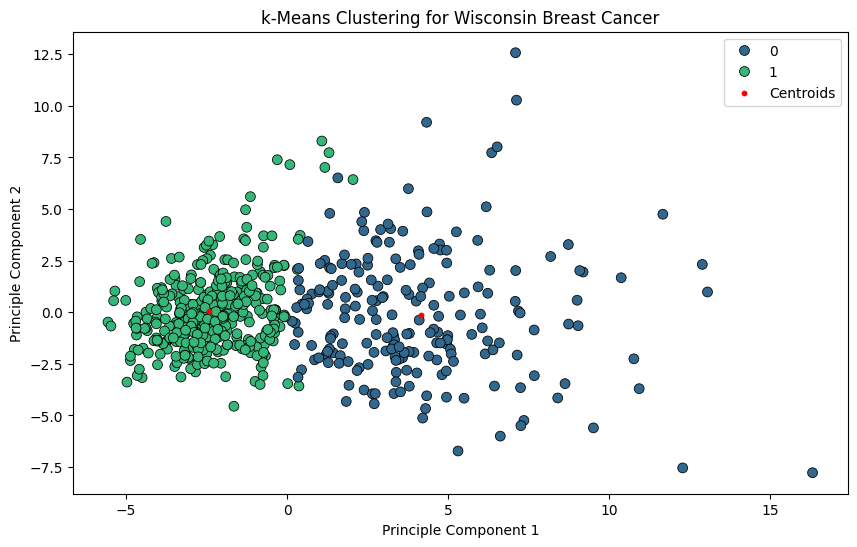

In [ ]:
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=2, n_init=5, random_state=42)
my_kmeans_piplelines = Pipeline(steps=[('preprocessor1', preproccesor1),
                                       ('pca', pca),
                              ('kmeans', kmeans)
                             ])
kmeans_data = my_kmeans_piplelines.fit_predict(X)
trained_kmeans = my_kmeans_piplelines.named_steps['kmeans']

plt.figure(figsize = (10, 6))
sns.scatterplot(x = pca_data[:, 0], y= pca_data[:,1], hue = kmeans_data, palette = 'viridis', s = 50, edgecolor = 'k')
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], s = 10, c = 'red', label = 'Centroids')
plt.xlabel('Principle Component 1')
plt.ylabel('Principle Component 2')
plt.title('k-Means Clustering for Wisconsin Breast Cancer')
plt.legend()
plt.show()

# Gaussian Mixture Model

Unlike K-Means algorithm, the Gaussian Mixture Model assumes that the data points were generated by "k" number of overlapping Gaussian Distribution, one for each of the k-clusters. It computes the mean, covariance matrix and mixing weight by iteratively using the Expectation-Maximization Algorithm. Gaussian Mixture Model initiates by using KMeans++ to result in the most optimal clustering of the data cloud. Based on the clustering done by KMeans++, a multimodal probability distribution curve with "k" peaks is formed. The multimodal curve is broken down into "k" gaussian distribution. The set of input variables (the coordinates) that define an instance/point is plotted on the gaussian distribution. The likelihood of that instance belonging to a specific gaussian distribution is calculated using the distribution's mean and covariance. A point can be closer to a mean of a cluster but may have a higher likelihood of belonging to another. During Expectation step, based on these likelihoods and the mixing weight of the specific dstribution, the percentage probability of the point belonging to a specific cluster is calculated , which is ultimately known as the responsibility using the Gaussian Bell-Curve Formula. This is a soft assignment.  Based on the responibiltiy calculated for each point with respect to each distribution, the weighted average of each distribution is calculated  to compute the new mean, new covariance matrix and the new mixing weight. It iterates through the E-M algorithm till the values stop changing


The GMM model on the WBCD intitally divides the data cloud into two clusters centered around a mean using kmeans++ algorithm. The resulting probability distribution is a multi-modal distribution resulting from two gaussian distribution. Using the Bell-Curve formula for likelihood, the point's likelihood belonging to each of the distribution is calculated and then the point's probability percentage (the responsibilty) is calculated for DISTRIBUTION A and B. It assigns soft probabilities to each of the data points and updates the mean, the covariance matrix and the mixing weight after the Expectation step is completed. It iteratively computes teh Expectation-Maximization algorithm until the mean, the covariance and the mixing weights stop changing. This computational method result in clustering the data clouds which are not isotropic, sort of fitting an eclipse of tilt and spread over the data cluster. However, similar to kmeans, it does not perform well on non-convex clusters.

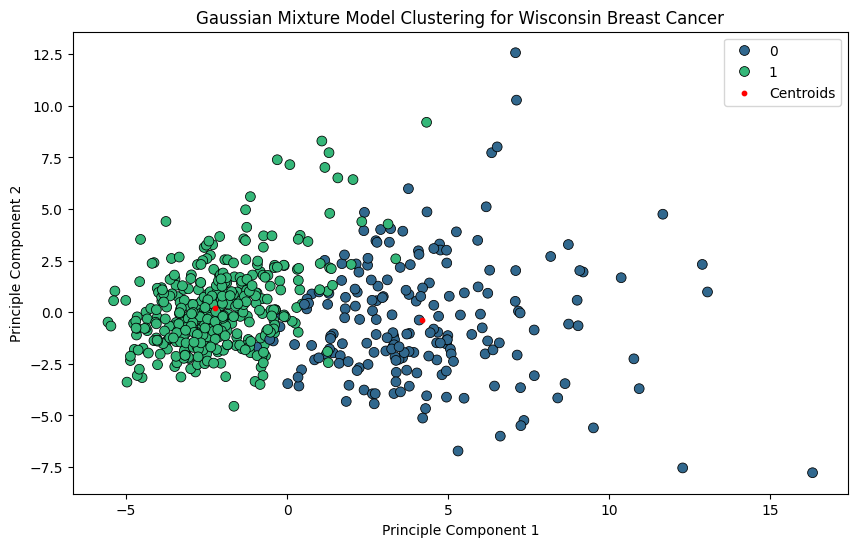

In [ ]:
from sklearn.mixture import GaussianMixture
gmm = GaussianMixture(n_components=2, covariance_type='tied', random_state=42)
my_gmm_pipeline = Pipeline(steps=[
    ('preprocessor1', preproccesor1),
    ('pca', pca),
    ('gmm', gmm)
])

gmm_data = my_gmm_pipeline.fit_predict(X)
trained_gmm = my_gmm_pipeline.named_steps['gmm']

plt.figure(figsize = (10, 6))
sns.scatterplot(x = pca_data[:, 0], y= pca_data[:,1], hue = gmm_data, palette = 'viridis', s = 50, edgecolor = 'k')
plt.scatter(trained_gmm.means_[:, 0], trained_gmm.means_[:, 1], s = 10, c = 'red', label = 'Centroids')
plt.xlabel('Principle Component 1')
plt.ylabel('Principle Component 2')
plt.title('Gaussian Mixture Model Clustering for Wisconsin Breast Cancer')
plt.legend()
plt.show()

#Using Adjusted Randex Index for Model Evaluation

Since the ground-truth labels are available, the model can evaluated using one of the various external meterics. The models are evaluated using Rand Index due to its high interpretability and easy to compare score metrics. Rand Index pairs two instances together. Using its real index, it checks it ground truth and the model's prediction for the instance. A pair is considered correct, if the ground truth of the pair in the same cluster and the models cluster it as such, and also if they do actually belong in different cluster and the model clusters it as such. It computes the True Positive, True Negative, False Positives, False Negatives

For Eg. consider 4 instances [1. M, 2. M, 3. B, 4. B]:
the model predicts on the same index [1. 1, 2. 1, 3. 0, 4. 0]

Rand Index takes a pair at random, index 2 and 4,
ground truth of these are [M, B] --> THEY DO NOT BELONG TO THE SAME CLUSTER
model's prediction [1,0] --> They are predicted to not belong in the same clsuter and hence results in True Positives

However, Rand Index does not consider the chance of the clustering assignment being random, a guess. Adjusted Rand Index works upon this by correcting it for chance. If a clustering assignment is a completely a guess, ARI penalizes it to 0.



In [ ]:
from sklearn.metrics import adjusted_rand_score

kmeans_score = adjusted_rand_score(y, kmeans_data)
gmm_score = adjusted_rand_score(y, gmm_data)

print(f"Adjusted Rand Index for K-Means: {kmeans_score: .4f} ")
print(f"Adjusted Rand Index for GMM: {gmm_score: .4f}")

from sklearn.metrics.cluster import rand_score
kmeans1_score = rand_score(y, kmeans_data)
gmm1_score = rand_score(y, gmm_data)

print(f"Rand Index for K-Means: {kmeans1_score: .4f} ")
print(f"Rand Index for GMM: {gmm1_score: .4f}")


Adjusted Rand Index for K-Means:  0.7249 
Adjusted Rand Index for GMM:  0.8371
Rand Index for K-Means:  0.8630 
Rand Index for GMM:  0.9191


In [ ]:
from sklearn.metrics import adjusted_rand_score
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.pipeline import Pipeline

# Test different numbers of PCA components
component_options = [i for i in range(15,19)]

for n in component_options:
      # Build the PCA step
      pca = PCA(n_components=n)
      preprocessor1 = PowerTransformer(method = "yeo-johnson")

      # 1. K-Means Pipeline (Tuned initialization)
      kmeans_pipe = Pipeline([
          ('preprocessor1', preproccesor1),
          ('pca', pca),
          ('kmeans', KMeans(n_clusters=2, n_init=5, random_state=42))
      ])
      km_preds = kmeans_pipe.fit_predict(X)

      # 2. GMM Pipeline (Testing a stiffer covariance)
      gmm_pipe = Pipeline([
        ('preprocessor1', preproccesor1),
        ('pca', pca),
        ('gmm', GaussianMixture(n_components=2, covariance_type='tied', random_state=42))
      ])
      gmm_preds = gmm_pipe.fit_predict(X)

      #  Print the results for this number of components
      print(f"PCA Components: {n}")
      print(f"  K-Means ARI: {adjusted_rand_score(y, km_preds):.4f}")
      print(f"  GMM ARI:     {adjusted_rand_score(y, gmm_preds):.4f}\n")

PCA Components: 15
  K-Means ARI: 0.7249
  GMM ARI:     0.8371

PCA Components: 16
  K-Means ARI: 0.7249
  GMM ARI:     0.8177

PCA Components: 17
  K-Means ARI: 0.7249
  GMM ARI:     0.8177

PCA Components: 18
  K-Means ARI: 0.7249
  GMM ARI:     0.7986

